# Credit Scoring Model — Model Training and Evaluation
**Project:** Credit Scoring Model for Private Debt
**Context:** SME lending for a private debt fund
**Dataset:** Credit Risk Dataset — Kaggle (laotse/credit-risk-dataset)
**Author:** Patrick Rich Teye

---
This notebook takes the engineered dataset and produces a working default-prediction model.

1. Load the engineered data and audit the feature set before training
2. Fix two problems carried over from feature engineering: a duplicated ratio and target leakage in the sector risk tier
3. Split the data, then derive anything target-dependent on the training fold only
4. Train a logistic regression baseline and a random forest
5. Train a second variant that excludes the lender's own risk pricing, and compare
6. Evaluate on recall for the default class, not accuracy

**Why recall matters more than accuracy here.** Roughly 22 per cent of these loans default. A model that predicts "no default" for every borrower is about 78 per cent accurate and completely useless. In a private debt fund a missed default costs the principal. A false alarm costs one hour of analyst review. We tune for the first error, not the second.

---
*Personal project built on a public dataset. It uses no proprietary, client or employer data and does not represent the methods or views of any organisation.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, warnings, joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, precision_recall_curve)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
os.makedirs('../plots', exist_ok=True)
os.makedirs('../models', exist_ok=True)

RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


## 1. Load the Engineered Dataset

Produced by `feature_engineering_cs.ipynb`. If this file is missing, run that notebook first.

In [2]:
df = pd.read_csv('credit_data_engineered.csv')
print(f"Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")

y_all = df['loan_status']
print(f"\nDefault rate: {y_all.mean()*100:.1f}%  ({y_all.sum():,} defaults of {len(y_all):,} loans)")
print(f"Imbalance ratio: {(1-y_all.mean())/y_all.mean():.1f} : 1")
df.head()

Loaded: 32,581 rows, 23 columns
Missing values: 0

Default rate: 21.8%  (7,108 defaults of 32,581 loans)
Imbalance ratio: 3.6 : 1


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,loan_to_income,grade_numeric,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22,59000.0,40.0,35000,16.02,1,0.59,3,0.5932,4,...,0,0,0,1,0,0,0,0,1,0
1,21,9600.0,5.0,1000,11.14,0,0.10,2,0.1042,2,...,0,0,1,0,0,1,0,0,0,0
2,25,9600.0,1.0,5500,12.87,1,0.57,3,0.5729,3,...,1,0,0,0,0,0,0,1,0,0
3,23,65500.0,4.0,35000,15.23,1,0.53,2,0.5344,3,...,0,0,0,1,0,0,0,1,0,0
4,24,54400.0,8.0,35000,14.27,1,0.55,4,0.6434,3,...,0,0,0,1,0,0,0,1,0,0


## 2. Audit the Feature Set Before Training

This step is not decoration. Two problems came through feature engineering and both would damage the
model's credibility if they reached the README unexamined.

**Problem one — a duplicated ratio.** The raw dataset already ships `loan_percent_income`, which is
`loan_amnt / person_income`. The engineered `loan_to_income` is the same calculation. Two near-identical
columns do not break a random forest, but they split the importance score between them, so each one looks
half as predictive as the signal really is. Since the whole point of this project is a readable feature
importance story, one of them has to go.

We keep the engineered `loan_to_income` and drop the dataset's own column. The reason is worth knowing.
Feature engineering capped `person_income` at the 99th percentile, so `loan_to_income` is computed on the
capped income while `loan_percent_income` was computed by the data provider on the raw income. For the top
one per cent of earners the two disagree, and keeping the provider's version alongside a capped
`person_income` would let the model partially reconstruct the pre-cap income we deliberately removed. The
engineered column is the internally consistent one.

**Problem two — target leakage in the sector risk tier.** `sector_risk_score` was built by ranking
`loan_intent` categories on their observed default rates across the *entire* dataset. Those rates include
the rows that are about to become the test set. The feature therefore carries information about test-set
outcomes, and every metric computed against it is flattered. This is the single most common way a credit
model looks better in a notebook than it performs in production.

The fix is not to delete the feature. The idea behind it is sound and it is exactly what a credit analyst
would build. We rebuild it after the split, using training-fold default rates only.

In [3]:
# Confirm the duplication rather than assuming it
if 'loan_percent_income' in df.columns and 'loan_to_income' in df.columns:
    gap = (df['loan_percent_income'] - df['loan_to_income']).abs()
    corr = df['loan_percent_income'].corr(df['loan_to_income'])
    print(f"Correlation loan_percent_income vs loan_to_income: {corr:.6f}")
    print(f"Rows differing by more than 0.01: {(gap > 0.01).sum():,} of {len(gap):,}"
          f"  ({(gap > 0.01).mean()*100:.2f}%)")
    print(f"Largest absolute difference: {gap.max():.4f}")
    print("\nSame ratio. The differences are the income-capped rows plus provider rounding.")
    print("Keeping loan_to_income (built on capped income), dropping loan_percent_income.")

# Recover loan_intent from the one-hot columns so the tier can be rebuilt after the split
intent_cols = [c for c in df.columns if c.startswith('loan_intent_')]
print(f"\nIntent dummy columns found: {len(intent_cols)}")
df['loan_intent'] = df[intent_cols].idxmax(axis=1).str.replace('loan_intent_', '', regex=False)
print(df['loan_intent'].value_counts())

Correlation loan_percent_income vs loan_to_income: 0.998573
Rows differing by more than 0.01: 584 of 32,581  (1.79%)
Largest absolute difference: 0.1032

Same ratio. The differences are the income-capped rows plus provider rounding.
Keeping loan_to_income (built on capped income), dropping loan_percent_income.

Intent dummy columns found: 6
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64


In [4]:
# Columns to remove before training, each with a stated reason
drop_reasons = {
    'loan_percent_income': 'duplicate of loan_to_income, and computed on pre-cap income',
    'sector_risk_score':   'target-derived on full data — rebuilt after the split',
}
to_drop = [c for c in drop_reasons if c in df.columns]
for c in to_drop:
    print(f"drop  {c:<22} {drop_reasons[c]}")

work = df.drop(columns=to_drop)
print(f"\nWorking frame: {work.shape[1]} columns (includes target and the recovered loan_intent)")

drop  loan_percent_income    duplicate of loan_to_income, and computed on pre-cap income
drop  sector_risk_score      target-derived on full data — rebuilt after the split

Working frame: 22 columns (includes target and the recovered loan_intent)


## 3. Split First, Engineer Second

The split comes before anything that touches the target. Stratified, so both folds carry the same default
rate, and a fixed seed so every number in the README is reproducible.

In [5]:
feature_cols = [c for c in work.columns if c not in ('loan_status', 'loan_intent')]

X = work[feature_cols + ['loan_intent']]   # intent carried along, not yet a feature
y = work['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]:,} rows   default rate {y_train.mean()*100:.2f}%")
print(f"Test:  {X_test.shape[0]:,} rows   default rate {y_test.mean()*100:.2f}%")

Train: 26,064 rows   default rate 21.82%
Test:  6,517 rows   default rate 21.82%


In [6]:
# Rebuild the sector risk tier using TRAINING default rates only
train_rates = y_train.groupby(X_train['loan_intent']).mean().sort_values(ascending=False)
print("Default rate by loan intent — TRAINING FOLD ONLY")
print((train_rates * 100).round(1).to_string())

# Three tiers by rank: highest third HIGH, middle MEDIUM, lowest LOW
order = list(train_rates.index)
n = len(order)
tier_map = {}
for i, intent in enumerate(order):
    tier_map[intent] = 3 if i < n/3 else (2 if i < 2*n/3 else 1)

print("\nTier assignment (3 = HIGH, 2 = MEDIUM, 1 = LOW):")
for intent in order:
    print(f"  {intent:<20} {train_rates[intent]*100:5.1f}%   tier {tier_map[intent]}")

# Apply the training-derived map to both folds
X_train = X_train.assign(sector_risk_score=X_train['loan_intent'].map(tier_map)).drop(columns=['loan_intent'])
X_test  = X_test.assign(sector_risk_score=X_test['loan_intent'].map(tier_map)).drop(columns=['loan_intent'])

assert X_test['sector_risk_score'].notna().all(), "unseen intent in test fold"
print(f"\nFinal feature count: {X_train.shape[1]}")
print(list(X_train.columns))

Default rate by loan intent — TRAINING FOLD ONLY
loan_intent
DEBTCONSOLIDATION    27.8
MEDICAL              26.8
HOMEIMPROVEMENT      26.0
PERSONAL             20.2
EDUCATION            17.5
VENTURE              14.9

Tier assignment (3 = HIGH, 2 = MEDIUM, 1 = LOW):
  DEBTCONSOLIDATION     27.8%   tier 3
  MEDICAL               26.8%   tier 3
  HOMEIMPROVEMENT       26.0%   tier 2
  PERSONAL              20.2%   tier 2
  EDUCATION             17.5%   tier 1
  VENTURE               14.9%   tier 1

Final feature count: 21
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'cb_person_cred_hist_length', 'loan_to_income', 'grade_numeric', 'is_repeat_defaulter', 'interest_income_ratio', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTU

## 4. Handling the Class Imbalance

Two standard options. We use `class_weight='balanced'`, which tells the model that each default costs the
same as roughly three and a half non-defaults, rather than SMOTE, which invents synthetic borrowers.

That choice is deliberate. A credit committee will ask which loan files
sit behind a score. Every row in a class-weighted model is a real loan you can point to. With SMOTE, a
share of the training set is interpolated borrowers who never existed, and in a regulated lending context
that is an awkward sentence to say out loud. Class weighting also costs nothing to reproduce and does not
change between runs.

In [7]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Non-default to default ratio in training fold: {scale_pos:.2f} : 1")
print("Using class_weight='balanced' for both models.")

Non-default to default ratio in training fold: 3.58 : 1
Using class_weight='balanced' for both models.


## 5. Model A — Baseline Logistic Regression

The baseline exists so the random forest has something to beat. It is also the model a credit committee can
read directly: each coefficient is a signed, interpretable weight. Logistic regression needs its inputs on
a common scale, so it goes in a pipeline with a scaler. The random forest does not need scaling.

In [8]:
logreg = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))
])
logreg.fit(X_train, y_train)
print("Logistic regression trained.")

Logistic regression trained.


## 6. Model B — Random Forest

In [9]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)
print("Random forest trained.")

Random forest trained.


## 7. Evaluation

One helper so every model is scored identically and the README table can be copied straight out. Recall on
the default class is the column to read first.

In [10]:
def evaluate(name, model, X_te=None, y_te=None):
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    pred  = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    row = {
        'Model': name,
        'Accuracy':  accuracy_score(y_te, pred),
        'Precision': precision_score(y_te, pred, zero_division=0),
        'Recall':    recall_score(y_te, pred),
        'F1':        f1_score(y_te, pred),
        'AUC-ROC':   roc_auc_score(y_te, proba),
    }
    return row, pred, proba

results = []
row_lr, pred_lr, proba_lr = evaluate('Logistic Regression', logreg); results.append(row_lr)
row_rf, pred_rf, proba_rf = evaluate('Random Forest', rf);           results.append(row_rf)

scores = pd.DataFrame(results).set_index('Model').round(4)
print(scores.to_string())
print("\nRecall is the share of real defaults the model actually caught.")

                     Accuracy  Precision  Recall      F1  AUC-ROC
Model                                                            
Logistic Regression    0.7942     0.5185  0.7989  0.6288   0.8727
Random Forest          0.9285     0.9085  0.7475  0.8202   0.9311

Recall is the share of real defaults the model actually caught.


In [11]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, pred_lr, target_names=['Non-Default', 'Default'], digits=3))
print("\nRANDOM FOREST")
print(classification_report(y_test, pred_rf, target_names=['Non-Default', 'Default'], digits=3))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

 Non-Default      0.934     0.793     0.858      5095
     Default      0.518     0.799     0.629      1422

    accuracy                          0.794      6517
   macro avg      0.726     0.796     0.743      6517
weighted avg      0.843     0.794     0.808      6517


RANDOM FOREST
              precision    recall  f1-score   support

 Non-Default      0.933     0.979     0.955      5095
     Default      0.909     0.748     0.820      1422

    accuracy                          0.928      6517
   macro avg      0.921     0.863     0.888      6517
weighted avg      0.928     0.928     0.926      6517



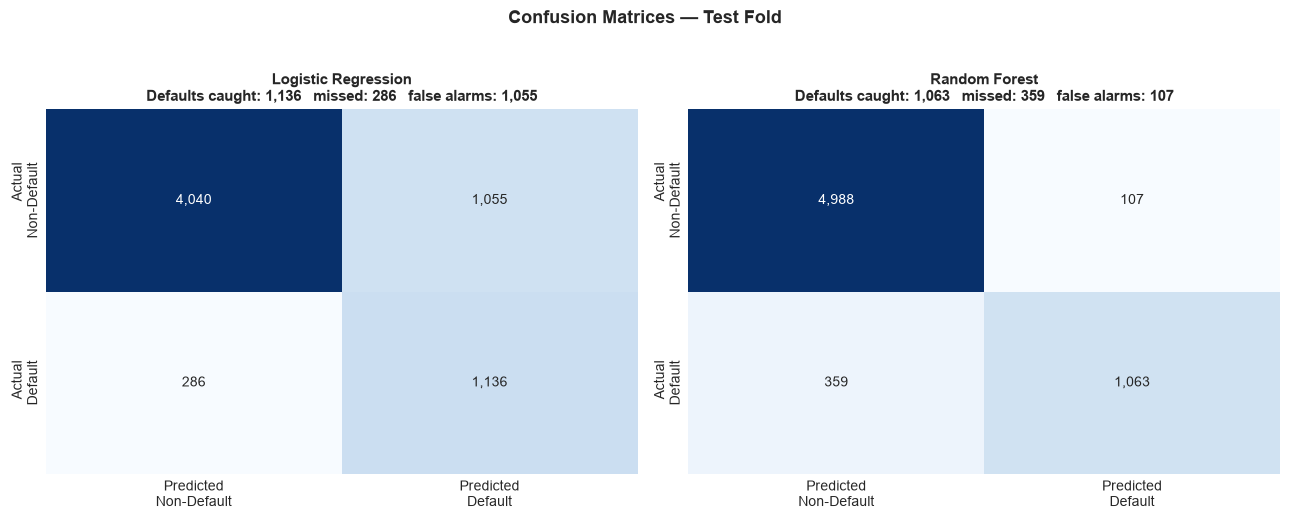

In [12]:
# Confusion matrices, read in loan counts rather than percentages
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [('Logistic Regression', pred_lr), ('Random Forest', pred_rf)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Predicted\nNon-Default', 'Predicted\nDefault'],
                yticklabels=['Actual\nNon-Default', 'Actual\nDefault'])
    missed = cm[1, 0]; caught = cm[1, 1]; false_alarm = cm[0, 1]
    ax.set_title(f'{name}\nDefaults caught: {caught:,}   missed: {missed:,}   false alarms: {false_alarm:,}',
                 fontsize=11, fontweight='bold')

plt.suptitle('Confusion Matrices — Test Fold', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../plots/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Tuning the Random Forest

A small, honest grid. Scored on recall for the default class, because that is the error that costs the fund
money. Three-fold stratified cross-validation on the training fold only, so the test fold stays untouched
until the final number.

In [13]:
param_grid = {
    'max_depth':        [8, 14, None],
    'min_samples_leaf': [2, 10],
}

# 6 combinations x 3 folds = 18 forest fits. Expect a few minutes on a laptop.
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight='balanced',
                           n_jobs=-1, random_state=RANDOM_STATE),
    param_grid, scoring='recall',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print(f"\nBest parameters: {grid.best_params_}")
print(f"Best cross-validated recall: {grid.best_score_:.4f}")
rf_tuned = grid.best_estimator_

Fitting 3 folds for each of 6 candidates, totalling 18 fits



Best parameters: {'max_depth': None, 'min_samples_leaf': 10}
Best cross-validated recall: 0.7650


In [14]:
row_tuned, pred_tuned, proba_tuned = evaluate('Random Forest (tuned)', rf_tuned)
results.append(row_tuned)
scores = pd.DataFrame(results).set_index('Model').round(4)
print(scores.to_string())

                       Accuracy  Precision  Recall      F1  AUC-ROC
Model                                                              
Logistic Regression      0.7942     0.5185  0.7989  0.6288   0.8727
Random Forest            0.9285     0.9085  0.7475  0.8202   0.9311
Random Forest (tuned)    0.9132     0.8297  0.7574  0.7919   0.9293


## 9. Model C — Without the Lender's Own Risk Pricing

This is the variant that makes the project worth reading.

`loan_grade` and `loan_int_rate` are not borrower characteristics. They are the lender's own verdict on the
borrower, already priced. A model built on them predicts default well, but much of what it has learned is
"the last underwriter thought this was risky". For a fund buying into an existing book that is genuinely
useful. For a fund originating its own deals it is close to circular, and it crowds out the borrower
signals we actually want to see in the feature importance chart.

So we train the same model without them and report both. The gap between the two is the honest measure of
how much independent signal sits in the borrower's own profile.

In [15]:
pricing_cols = [c for c in ['grade_numeric', 'loan_int_rate', 'interest_income_ratio'] if c in X_train.columns]
print(f"Excluding the lender's risk pricing: {pricing_cols}")
print("(interest_income_ratio is excluded too — it is built from loan_int_rate)")

X_train_b = X_train.drop(columns=pricing_cols)
X_test_b  = X_test.drop(columns=pricing_cols)

rf_behavioural = RandomForestClassifier(
    **{k: v for k, v in grid.best_params_.items()},
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
rf_behavioural.fit(X_train_b, y_train)

row_b, pred_b, proba_b = evaluate('Random Forest (borrower only)', rf_behavioural, X_test_b, y_test)
results.append(row_b)

scores = pd.DataFrame(results).set_index('Model').round(4)
print(scores.to_string())

gap = row_tuned['AUC-ROC'] - row_b['AUC-ROC']
print(f"\nAUC lost by removing the lender's risk pricing: {gap:.4f}")
print("A small gap means the borrower profile carries real independent signal.")
print("A large gap means most of the performance was borrowed from the lender's own pricing.")

Excluding the lender's risk pricing: ['grade_numeric', 'loan_int_rate', 'interest_income_ratio']
(interest_income_ratio is excluded too — it is built from loan_int_rate)


                               Accuracy  Precision  Recall      F1  AUC-ROC
Model                                                                      
Logistic Regression              0.7942     0.5185  0.7989  0.6288   0.8727
Random Forest                    0.9285     0.9085  0.7475  0.8202   0.9311
Random Forest (tuned)            0.9132     0.8297  0.7574  0.7919   0.9293
Random Forest (borrower only)    0.8532     0.6568  0.6850  0.6706   0.8723

AUC lost by removing the lender's risk pricing: 0.0570
A small gap means the borrower profile carries real independent signal.
A large gap means most of the performance was borrowed from the lender's own pricing.


## 10. ROC Comparison

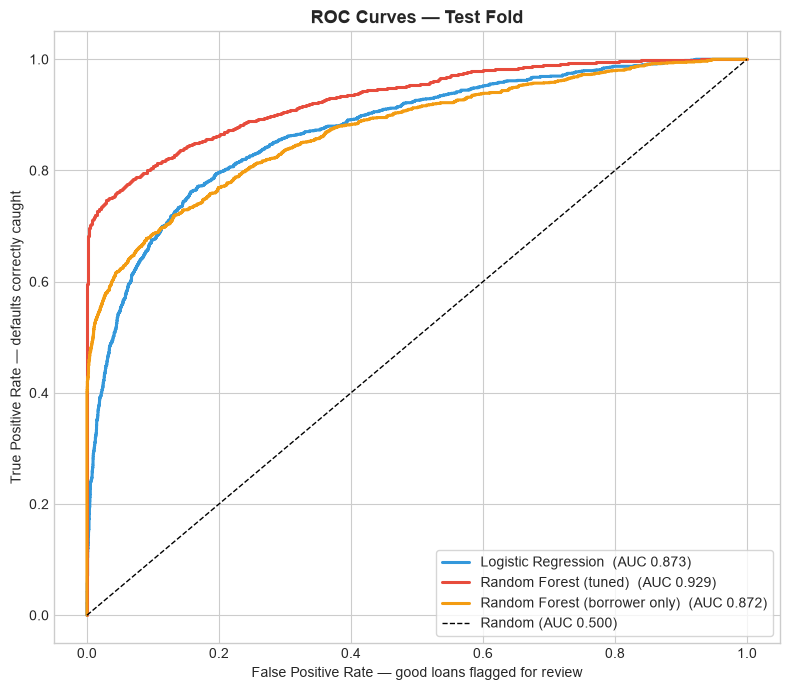

In [16]:
fig, ax = plt.subplots(figsize=(8, 7))
curves = [
    ('Logistic Regression', proba_lr, y_test, '#3498db'),
    ('Random Forest (tuned)', proba_tuned, y_test, '#e74c3c'),
    ('Random Forest (borrower only)', proba_b, y_test, '#f39c12'),
]
for name, proba, yt, colour in curves:
    fpr, tpr, _ = roc_curve(yt, proba)
    ax.plot(fpr, tpr, color=colour, linewidth=2.2,
            label=f'{name}  (AUC {roc_auc_score(yt, proba):.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC 0.500)')
ax.set_xlabel('False Positive Rate — good loans flagged for review', fontsize=10)
ax.set_ylabel('True Positive Rate — defaults correctly caught', fontsize=10)
ax.set_title('ROC Curves — Test Fold', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig('../plots/roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Feature Importance

Two charts side by side. The left one is dominated by the lender's grade and rate. The right one shows what
is left when those are removed, and that is the chart to read first, because it is the one that says
something the lender did not already know.

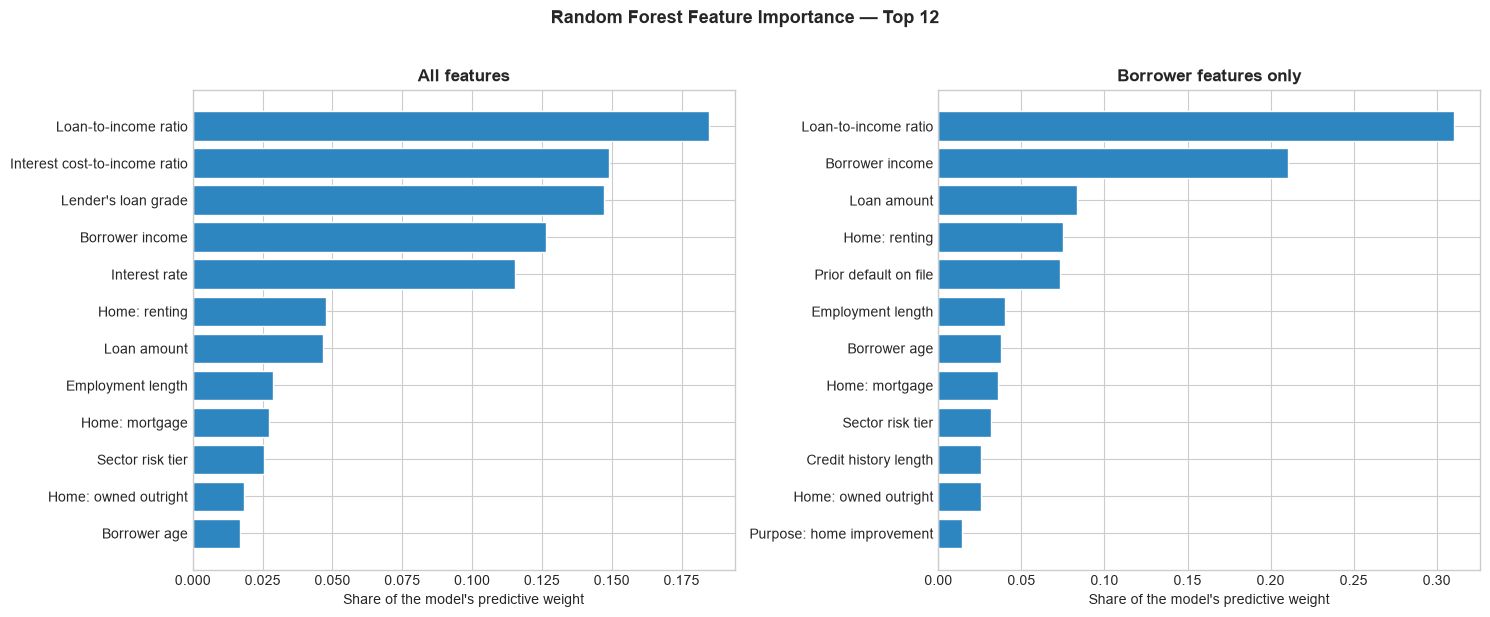

TOP 10 — ALL FEATURES
                       feature  importance
                loan_to_income    0.184721
         interest_income_ratio    0.149115
                 grade_numeric    0.147205
                 person_income    0.126549
                 loan_int_rate    0.115357
    person_home_ownership_RENT    0.047809
                     loan_amnt    0.046585
             person_emp_length    0.028793
person_home_ownership_MORTGAGE    0.027334
             sector_risk_score    0.025554

TOP 10 — BORROWER FEATURES ONLY
                       feature  importance
                loan_to_income    0.310520
                 person_income    0.210460
                     loan_amnt    0.083703
    person_home_ownership_RENT    0.074900
           is_repeat_defaulter    0.072992
             person_emp_length    0.039893
                    person_age    0.037421
person_home_ownership_MORTGAGE    0.035982
             sector_risk_score    0.031951
    cb_person_cred_hist_length    0.025837

In [17]:
FEATURE_LABELS = {
    'loan_to_income': 'Loan-to-income ratio',
    'interest_income_ratio': 'Interest cost-to-income ratio',
    'grade_numeric': "Lender's loan grade",
    'person_income': 'Borrower income',
    'loan_int_rate': 'Interest rate',
    'loan_amnt': 'Loan amount',
    'person_emp_length': 'Employment length',
    'person_age': 'Borrower age',
    'cb_person_cred_hist_length': 'Credit history length',
    'is_repeat_defaulter': 'Prior default on file',
    'sector_risk_score': 'Sector risk tier',
    'person_home_ownership_RENT': 'Home: renting',
    'person_home_ownership_MORTGAGE': 'Home: mortgage',
    'person_home_ownership_OWN': 'Home: owned outright',
    'person_home_ownership_OTHER': 'Home: other',
    'loan_intent_DEBTCONSOLIDATION': 'Purpose: debt consolidation',
    'loan_intent_EDUCATION': 'Purpose: education',
    'loan_intent_HOMEIMPROVEMENT': 'Purpose: home improvement',
    'loan_intent_MEDICAL': 'Purpose: medical',
    'loan_intent_PERSONAL': 'Purpose: personal',
    'loan_intent_VENTURE': 'Purpose: venture',
}

def importance_frame(model, cols):
    return (pd.DataFrame({'feature': cols, 'importance': model.feature_importances_})
              .sort_values('importance', ascending=False).reset_index(drop=True))

imp_full = importance_frame(rf_tuned, X_train.columns)
imp_bhv  = importance_frame(rf_behavioural, X_train_b.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (frame, title) in zip(axes, [(imp_full, 'All features'),
                                     (imp_bhv, 'Borrower features only')]):
    top = frame.head(12).iloc[::-1]
    ax.barh(top['feature'].map(lambda f: FEATURE_LABELS.get(f, f)), top['importance'],
            color='#2E86C1', edgecolor='white')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Share of the model\'s predictive weight')

plt.suptitle('Random Forest Feature Importance — Top 12', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../plots/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("TOP 10 — ALL FEATURES")
print(imp_full.head(10).to_string(index=False))
print("\nTOP 10 — BORROWER FEATURES ONLY")
print(imp_bhv.head(10).to_string(index=False))

## 12. Interpretation

The five strongest features in the borrower-only model, read in lending language rather than modelling language.

| Feature | Importance | What it means for a lending decision |
|---|---|---|
| Loan-to-income ratio | 0.311 | The share of income committed to the loan is the single strongest signal. Affordability, not history, is what separates the book. |
| Borrower income | 0.210 | Income level matters independently of the ratio. Two borrowers at the same ratio can have very different capacity to absorb a shock. |
| Loan amount | 0.084 | Ticket size adds signal beyond the ratio. At the same income, larger facilities carry more risk. |
| Home: renting | 0.075 | Renting rather than owning or holding a mortgage is a risk marker, read as a proxy for balance sheet depth and not as a judgement about the borrower. |
| Prior default on file | 0.073 | Prior default matters, but it ranks below affordability. |

**1. Which model would go in front of a credit committee?** The tuned random forest. The logistic regression
catches slightly more defaults (recall 0.7989) but about half the loans it flags are false alarms (precision
0.5185), which is more review volume than a small team can absorb. The tuned forest keeps recall close to that
level, at 0.7574, with precision of 0.8297. Accuracy is not the deciding number.

**2. What does it get wrong?** It still misses roughly one default in four. That is the costlier direction,
because a missed default costs principal while a false alarm costs an hour of analyst time. Tuning on recall
pushes the model toward the safer error, but does not remove the other one.

**3. What would be needed before trusting it on a real private debt deal?** Repayment behaviour across
periods, sector and geography fields, and some treatment of currency risk on locally denominated loans. This is
a single-period consumer dataset, so it cannot see a borrower deteriorating over time.

## 13. Persist the Models

Saved so the scorecard notebook can load a trained model instead of retraining it.

In [18]:
joblib.dump(rf_tuned,        '../models/rf_tuned.joblib')
joblib.dump(rf_behavioural,  '../models/rf_borrower_only.joblib')
joblib.dump(logreg,          '../models/logreg_baseline.joblib')
joblib.dump(list(X_train.columns),   '../models/feature_columns.joblib')
joblib.dump(list(X_train_b.columns), '../models/feature_columns_borrower_only.joblib')
joblib.dump(tier_map,        '../models/sector_tier_map.joblib')

scores.to_csv('model_results.csv')
print("Saved to models/ and model_results.csv")
print(scores.to_string())

Saved to models/ and model_results.csv
                               Accuracy  Precision  Recall      F1  AUC-ROC
Model                                                                      
Logistic Regression              0.7942     0.5185  0.7989  0.6288   0.8727
Random Forest                    0.9285     0.9085  0.7475  0.8202   0.9311
Random Forest (tuned)            0.9132     0.8297  0.7574  0.7919   0.9293
Random Forest (borrower only)    0.8532     0.6568  0.6850  0.6706   0.8723


## 14. Summary

| Step | Decision | Reason |
|---|---|---|
| Duplicate feature | Dropped `loan_percent_income` | Same ratio as `loan_to_income`, but computed on pre-cap income; keeping both split the importance score |
| Target leakage | Rebuilt `sector_risk_score` on the training fold only | The original version ranked sectors using test-set outcomes |
| Split | 80 / 20 stratified, seed 42 | Reproducible, and both folds carry the same default rate |
| Imbalance | `class_weight='balanced'` | Every training row stays a real loan file, which matters for committee scrutiny |
| Tuning metric | Recall on the default class | A missed default costs principal; a false alarm costs an hour of review |
| Model variants | With and without the lender's grade and rate | Separates independent borrower signal from the previous underwriter's verdict |

---
**Next:** `scorecard_cs.ipynb`, the scorecard layer. Convert `predict_proba` output into score bands
mapped to Low, Medium and High risk tiers, each with a recommended action of approve, review or decline.
Load the model from `models/rf_tuned.joblib` rather than retraining.